# 07 · LoRA fine-tuning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/epjover/chronos2-in-practice/blob/main/notebooks/07_finetune_lora.ipynb)

Companion notebook for *Chronos-2 in Practice (4/7)*. **Needs a GPU** (local or Colab T4).

**What you will learn**

- A temporal split that cannot leak: train, validation and test periods in time order, with
  every validation window taking its context only from earlier data.
- `Chronos2Pipeline.fit(..., finetune_mode="lora")` end to end: adapter rank, learning rate,
  early stopping, saving and reloading.
- What one LoRA run costs: wall-clock time, peak VRAM, artifact size, trainable parameters.
- Whether rank 4, 8 or 16 matters, with **three seeds per rank**, so that the difference
  between two ranks can be compared with the difference between two runs of the same rank.
- How to choose the training budget (steps and learning rate) **on validation windows of the
  target series**, and only then look at the test year.
- Three traps between `fit()` returning and a trustworthy evaluation, and why this repository
  reloads the checkpoint from disk instead of scoring the object `fit` hands back.

Runtime: ~2 h 15 min on an RTX 3070: 9 runs for the rank sweep, 3 more to choose the budget, up
to 2 more seeds of the chosen budget (FAST_MODE: ~6 min).

In [1]:
# On Google Colab, clone the companion repo and install it (Colab's own PyTorch is kept).
# Locally, `uv sync` already installed everything and this cell does nothing.
import sys

if "google.colab" in sys.modules:
    !git clone --depth 1 https://github.com/epjover/chronos2-in-practice.git
    %cd chronos2-in-practice
    %pip install -q .
    import importlib

    importlib.invalidate_caches()

In [2]:
import time

import pandas as pd
import torch
from huggingface_hub.utils import logging as hub_logging
from IPython.display import Image, display
from transformers.utils import logging as transformers_logging

from c2p.config import SEED, get_device, get_paths, is_fast_mode, set_seed
from c2p.data import spain_energy_frame, validate_and_prepare
from c2p.eval import (
    MODEL_COL,
    backtest,
    evaluate,
    skill_table,
    summarize,
    summarize_runs,
)
from c2p.experiments import (
    DAY_AHEAD_BLOCK,
    FREQ,
    LOAD,
    TRAIN_END,
    VALIDATION_END,
    day_ahead_config,
    validation_config,
)
from c2p.finetune import (
    finetune,
    lora_config,
    temporal_split,
    to_fit_inputs,
    to_univariate_series,
    window_series,
)
from c2p.models import Chronos2Forecaster, load_chronos2
from c2p.plots.evaluation import plot_skill_scores
from c2p.plotting import save_figure, set_style
from c2p.results import load_results, run_metadata, save_results
from c2p.schema import ID_COL, TIMESTAMP_COL

FAST_MODE = is_fast_mode(default=False)
PATHS = get_paths(fast_mode=FAST_MODE)
set_seed()
DEVICE = get_device()
set_style()
hub_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

if DEVICE != "cuda":
    print(
        "WARNING: no GPU visible. This notebook fine-tunes a 120M-parameter model; on a CPU a\n"
        "single run takes hours. Open it in Colab (Runtime > Change runtime type > T4 GPU)."
    )
for key, value in run_metadata(device=DEVICE, fast_mode=FAST_MODE).items():
    print(f"{key:>20}: {value}")

              python: 3.11.17
              device: cuda
           fast_mode: False
                seed: 42
          run_at_utc: 2026-11-26 13:42
                 cpu: 12th Gen Intel(R) Core(TM) i9-12900K
     cores_available: 8
       torch_threads: 8
                 gpu: NVIDIA GeForce RTX 3070 (8 GiB)
 chronos-forecasting: 2.3.2
               torch: 2.14.1
              pandas: 3.1.0
               numpy: 2.4.6
                 fev: 0.10.0
       statsforecast: 2.0.1


## 1. A split that cannot leak

Fine-tuning makes leakage much easier than zero-shot inference does, because the model now has
an opportunity to memorise. Three periods in time order are the minimum:

- **train**: everything up to mid-2017, used for the gradient updates;
- **validation**: the second half of 2017, used for early stopping and for every choice this
  notebook makes (section 5);
- **test**: 2018, the same year Part 2 evaluated on, looked at once the choices are made.

`window_series` is the detail that matters for the validation set: instead of handing the model
the validation period as one long series, it cuts it into forecast windows and makes each one a
separate series whose context comes from *earlier* data only. Validation loss then measures the
same thing as the test backtest, rather than the model's ability to continue a series it is
already inside.

There is also a data decision here. One national load series is thin training data, so every numeric column of the Spanish table (load, price, and generation by source) becomes its own univariate series with `to_univariate_series`. That is a domain fine-tune: "learn Spanish electricity," not "learn this one series".

The validation period is used in two ways. `fit` computes its validation loss on the 26 series,
one window a week, and that drives early stopping. (One window a week means that all 27 forecast
the same weekday, a Saturday: enough to decide when to stop, not a sample to score a model on.) The choice of a budget in section 5 uses
something closer to the question: a day-ahead backtest of the *load* over the 184 days of the
validation period, with the same harness and metrics as the test year.

In [3]:
HORIZON = 24
CONTEXT = 2048
STEPS = 50 if FAST_MODE else 1000
EVAL_STEPS = 10 if FAST_MODE else 100
BATCH = 32
RANKS = (8,) if FAST_MODE else (4, 8, 16)
SEEDS = (SEED,) if FAST_MODE else (SEED, SEED + 1, SEED + 2)

raw = spain_energy_frame()
numeric = [column for column in raw.columns if column not in (ID_COL, TIMESTAMP_COL)]
frame, report = validate_and_prepare(raw[[ID_COL, TIMESTAMP_COL, *numeric]], freq=FREQ, target=LOAD)
univariate = to_univariate_series(frame, numeric)
split = temporal_split(
    univariate, val_start=TRAIN_END + pd.Timedelta(hours=1), test_start="2018-01-01"
)
print(f"{univariate[ID_COL].nunique()} univariate series from the Spanish table")
print(
    f"train {split.train[TIMESTAMP_COL].min()} to {split.train[TIMESTAMP_COL].max()} "
    f"({len(split.train):,} rows)"
)
print(
    f"val   {split.val[TIMESTAMP_COL].min()} to {split.val[TIMESTAMP_COL].max()} "
    f"({len(split.val):,} rows)"
)
print(
    f"test  {split.test[TIMESTAMP_COL].min()} to {split.test[TIMESTAMP_COL].max()} "
    f"({len(split.test):,} rows)"
)

train_inputs = to_fit_inputs(split.train, freq=FREQ, prediction_length=HORIZON)
val_frame = window_series(
    split.train, split.val, prediction_length=HORIZON, freq=FREQ, step=168, max_context=CONTEXT
)
val_inputs = to_fit_inputs(val_frame, freq=FREQ, prediction_length=HORIZON)
print(f"\nfit inputs: {len(train_inputs)} training series, {len(val_inputs)} validation windows")

26 univariate series from the Spanish table
train 2014-12-31 23:00:00 to 2017-06-30 21:00:00 (569,062 rows)
val   2017-06-30 22:00:00 to 2017-12-31 23:00:00 (114,868 rows)
test  2018-01-01 00:00:00 to 2018-12-31 22:00:00 (227,734 rows)

fit inputs: 26 training series, 702 validation windows


## 2. The reference to beat

Before training anything: the zero-shot number, on the test windows and on the validation
windows. The test backtest is the same series, the same 365 day-ahead windows and the same
metrics as Part 2, so if fine-tuning does not beat this, that is the result. The validation
backtest is the same protocol moved back to the second half of 2017.

In [4]:
# The test series and protocol are those of article 2, so the numbers are comparable.
LOAD_FRAME = frame[[ID_COL, TIMESTAMP_COL, LOAD]]
SPLITS = {
    "test": (LOAD_FRAME, day_ahead_config(FAST_MODE, max_context=CONTEXT)),
    "validation": (
        LOAD_FRAME[LOAD_FRAME[TIMESTAMP_COL] <= VALIDATION_END],
        validation_config(FAST_MODE, max_context=CONTEXT),
    ),
}

zero_shot = Chronos2Forecaster(load_chronos2(device=DEVICE), name="zero-shot")
zero = {
    name: evaluate(backtest(zero_shot, split_frame, config), split_frame, config)
    for name, (split_frame, config) in SPLITS.items()
}
for name, metrics in zero.items():
    print(
        f"zero-shot on the {name} windows ({metrics['window'].nunique()}): "
        f"WQL {metrics['WQL'].mean():.4f}, 80% coverage {metrics['coverage_80'].mean():.1%}"
    )
del zero_shot

zero-shot on the test windows (365): WQL 0.0388, 80% coverage 73.4%
zero-shot on the validation windows (184): WQL 0.0390, 80% coverage 69.2%


## 3. One LoRA run, and what it costs

LoRA freezes the pretrained weights and trains two small matrices per targeted layer; the rank
`r` sets their width. The defaults here reproduce Chronos-2's own targets (the attention
projections and the output patch embedding) and AutoGluon's settings: a learning rate of 1e-5
and 1,000 steps.

Three things happen between `fit()` returning and a number you can trust, and `c2p.finetune`
handles all three; they are the reason this notebook does not call `fit` directly:

1. Without validation data the returned pipeline stays in **training mode**, so dropout makes
   every forecast random.
2. After a full fine-tune with mixed precision the forward pass stays wrapped in **bfloat16
   autocast**, shifting forecasts by a fraction of a percent.
3. `fit` enables **TF32** process-wide on Ampere or newer GPUs and never switches it off, which
   silently changes every later forecast in the session.

`finetune()` returns the saved checkpoint reloaded from disk and restores TF32, so the model you
evaluate is the model you saved.

Every run in this notebook goes through one function: train an adapter, score it on the splits
asked for, keep its costs, free the GPU. The learning-rate schedule decays linearly to zero over
`num_steps`, so a run with more steps is a different schedule, not the same run left on longer.

In [5]:
def train_and_score(
    name: str, *, rank: int, seed: int, steps: int, learning_rate: float, splits: tuple[str, ...]
) -> tuple[dict[str, object], dict[str, pd.DataFrame]]:
    """Fine-tune one adapter and return its cost row and its metrics on each split."""
    result = finetune(
        load_chronos2(device=DEVICE),
        train_inputs,
        val_inputs=val_inputs,
        mode="lora",
        prediction_length=HORIZON,
        num_steps=steps,
        learning_rate=learning_rate,
        batch_size=BATCH,
        context_length=CONTEXT,
        output_dir=PATHS.models / name,
        lora_config=lora_config(r=rank),
        early_stopping_patience=3,
        eval_steps=EVAL_STEPS,
        seed=seed,
        overwrite=True,
    )
    model = Chronos2Forecaster(result.pipeline, name=name)
    metrics = {}
    for split_name in splits:
        split_frame, config = SPLITS[split_name]
        metrics[split_name] = evaluate(backtest(model, split_frame, config), split_frame, config)
    cost = {
        "run": name,
        "rank": rank,
        "seed": seed,
        "learning_rate": learning_rate,
        **result.summary(),
    }
    print(
        f"{name}: {result.trainable_parameters:,} trainable "
        f"({result.trainable_parameters / result.total_parameters:.2%}), "
        f"{result.train_seconds / 60:.1f} min, peak VRAM {result.peak_vram_mb:.0f} MB, "
        f"adapter {result.artifact_mb:.1f} MB, best step {result.best_step} of {result.steps}, "
        f"validation loss {result.best_eval_loss:.4f}"
        + "".join(f", {s} WQL {m['WQL'].mean():.4f}" for s, m in metrics.items())
    )
    del result, model
    torch.cuda.empty_cache()
    return cost, metrics

## 4. Ranks, and seeds

Three ranks, each trained three times with a different seed (the seed sets the order of the
training windows). Without the repeats there is no way to tell a difference between rank 4 and
rank 16 from the difference between two runs of rank 8.

The first run of rank 8 is also scored on the validation windows: it is the library-default
candidate of section 5.

In [6]:
start = time.perf_counter()
costs, test_frames = [], [zero["test"]]
default_validation = None
for rank in RANKS:
    for seed in SEEDS:
        is_reference = rank == 8 and seed == SEED
        cost, metrics = train_and_score(
            f"lora_r{rank}_s{seed}",
            rank=rank,
            seed=seed,
            steps=STEPS,
            learning_rate=1e-5,
            splits=("test", "validation") if is_reference else ("test",),
        )
        costs.append(cost)
        test_frames.append(metrics["test"])
        if is_reference:
            default_validation = metrics["validation"]
print(f"\n{len(costs)} runs in {(time.perf_counter() - start) / 60:.0f} min")
print("Saved", save_results(pd.DataFrame(costs), "07_lora_costs", PATHS).name)
print(
    "Saved",
    save_results(pd.concat(test_frames, ignore_index=True), "07_lora_metrics", PATHS).name,
)

lora_r4_s42: 603,456 trainable (0.50%), 5.0 min, peak VRAM 3755 MB, adapter 2.3 MB, best step 1000 of 1000, validation loss 3.1351, test WQL 0.0377
lora_r4_s43: 603,456 trainable (0.50%), 5.1 min, peak VRAM 3756 MB, adapter 2.3 MB, best step 1000 of 1000, validation loss 3.1356, test WQL 0.0378
lora_r4_s44: 603,456 trainable (0.50%), 5.1 min, peak VRAM 3756 MB, adapter 2.3 MB, best step 1000 of 1000, validation loss 3.1480, test WQL 0.0379
lora_r8_s42: 1,206,912 trainable (1.00%), 5.2 min, peak VRAM 3767 MB, adapter 4.6 MB, best step 1000 of 1000, validation loss 3.0962, test WQL 0.0374, validation WQL 0.0372
lora_r8_s43: 1,206,912 trainable (1.00%), 5.2 min, peak VRAM 3767 MB, adapter 4.6 MB, best step 1000 of 1000, validation loss 3.0969, test WQL 0.0375
lora_r8_s44: 1,206,912 trainable (1.00%), 5.1 min, peak VRAM 3767 MB, adapter 4.6 MB, best step 1000 of 1000, validation loss 3.1087, test WQL 0.0374
lora_r16_s42: 2,413,824 trainable (1.98%), 5.1 min, peak VRAM 3790 MB, adapter 9.2 

Each run against the zero-shot model, then each rank with its three seeds averaged window by
window (`average_runs`): the second table estimates what *a* run of that rank gives, the first
shows how far single runs sit from it. Intervals resample blocks of seven consecutive days.

In [7]:
lora_metrics = load_results("07_lora_metrics", PATHS)
run_skill = skill_table(
    lora_metrics, baseline="zero-shot", metric="WQL", block_length=DAY_AHEAD_BLOCK
)
print("Saved", save_results(run_skill, "07_lora_run_skill", PATHS).name)

RANK_RUNS = {f"lora_r{rank}": [f"lora_r{rank}_s{seed}" for seed in SEEDS] for rank in RANKS}
rank_summary, rank_metrics = summarize_runs(
    lora_metrics, RANK_RUNS, baseline="zero-shot", block_length=DAY_AHEAD_BLOCK
)
print("Saved", save_results(rank_summary, "07_lora_rank_summary", PATHS).name)
rank_skill = skill_table(
    rank_metrics, baseline="zero-shot", metric="WQL", block_length=DAY_AHEAD_BLOCK
)
print("Saved", save_results(rank_skill, "07_lora_skill", PATHS).name)
rank_summary.round(4)

Saved 07_lora_run_skill.csv
Saved 07_lora_rank_summary.csv
Saved 07_lora_skill.csv


,model,n_runs,WQL,mean_change,skill,ci_low,ci_high,win_rate,run_skill_min,run_skill_max,coverage_80,coverage_98
0,lora_r4,3,0.0378,-0.0245,0.0191,0.0070,0.0305,0.5507,0.0181,0.0214,0.7318,0.9448
1,lora_r8,3,0.0374,-0.0346,0.0265,0.0045,0.0478,0.5589,0.0229,0.0298,0.7217,0.9449
2,lora_r16,3,0.0374,-0.0338,0.0215,-0.0115,0.0528,0.5370,0.0146,0.0269,0.7057,0.9402


Between ranks (seed-averaged): 0.7 points. Between single runs: 1.5 points.


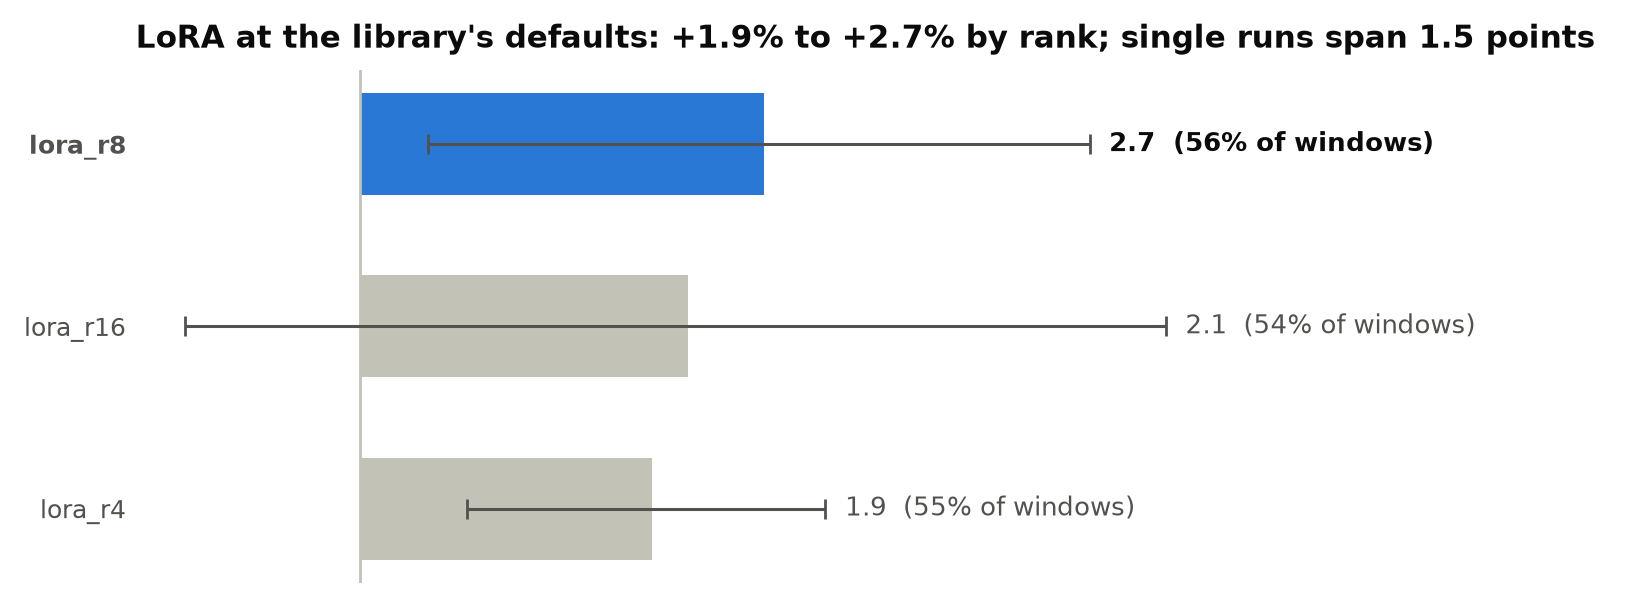

In [8]:
lora_skill = load_results("07_lora_skill", PATHS)
rank_summary = load_results("07_lora_rank_summary", PATHS)
spread = rank_summary["run_skill_max"].max() - rank_summary["run_skill_min"].min()
between = rank_summary["skill"].max() - rank_summary["skill"].min()
title = (
    f"LoRA at the library's defaults: {rank_summary['skill'].min():+.1%} to "
    f"{rank_summary['skill'].max():+.1%} by rank; single runs span {100 * spread:.1f} points"
)
ax = plot_skill_scores(
    lora_skill,
    highlight=str(lora_skill[lora_skill["model"] != "zero-shot"].iloc[0]["model"]),
    title=title,
    xlabel="WQL improvement over the zero-shot model (%), three seeds averaged",
)
(figure_path,) = save_figure(ax.figure, "07_lora_skill", PATHS.figures)
display(Image(filename=figure_path, width=800))
print(
    f"Between ranks (seed-averaged): {100 * between:.1f} points. "
    f"Between single runs: {100 * spread:.1f} points."
)

## 5. A budget chosen on validation

The four runs below are rank 8 with one seed and differ in what the library's defaults fix: the
number of steps and the peak learning rate. In the default run the best validation loss is at
the last step, so the question of whether more training helps is open.

The choice is made on the **validation backtest of the load**: skill against the zero-shot
model over the 184 day-ahead windows of the second half of 2017, with the same harness as the
test year. The test metrics of the candidates are computed in the same pass and saved, but the
choice does not read them; they are shown afterwards, as a check on how well the validation
half-year predicted the test year.

In [9]:
CANDIDATES = {
    f"{STEPS:,} steps, lr 1e-5": (STEPS, 1e-5),
    f"{4 * STEPS:,} steps, lr 1e-5": (4 * STEPS, 1e-5),
    f"{STEPS:,} steps, lr 1e-4": (STEPS, 1e-4),
    f"{4 * STEPS:,} steps, lr 1e-4": (4 * STEPS, 1e-4),
}
DEFAULT = next(iter(CANDIDATES))
default_run = f"lora_r8_s{SEED}"

start = time.perf_counter()
budget_costs = [next(cost for cost in costs if cost["run"] == default_run) | {"candidate": DEFAULT}]
validation_frames = [zero["validation"], default_validation.assign(**{MODEL_COL: DEFAULT})]
budget_test_frames = [
    zero["test"],
    lora_metrics[lora_metrics[MODEL_COL] == default_run].assign(**{MODEL_COL: DEFAULT}),
]
for label, (steps, learning_rate) in CANDIDATES.items():
    if label == DEFAULT:
        continue
    cost, metrics = train_and_score(
        f"lora_budget_{steps}_{learning_rate:g}",
        rank=8,
        seed=SEED,
        steps=steps,
        learning_rate=learning_rate,
        splits=("test", "validation"),
    )
    budget_costs.append(cost | {"candidate": label})
    validation_frames.append(metrics["validation"].assign(**{MODEL_COL: label}))
    budget_test_frames.append(metrics["test"].assign(**{MODEL_COL: label}))
print(f"\n{len(CANDIDATES) - 1} more runs in {(time.perf_counter() - start) / 60:.0f} min")
print("Saved", save_results(pd.DataFrame(budget_costs), "07_budget_costs", PATHS).name)
budget_validation = pd.concat(validation_frames, ignore_index=True)
print("Saved", save_results(budget_validation, "07_budget_validation_metrics", PATHS).name)
budget_test = pd.concat(budget_test_frames, ignore_index=True)
print("Saved", save_results(budget_test, "07_budget_test_metrics", PATHS).name)

lora_budget_4000_1e-05: 1,206,912 trainable (1.00%), 20.3 min, peak VRAM 3767 MB, adapter 4.6 MB, best step 4000 of 4000, validation loss 2.8732, test WQL 0.0364, validation WQL 0.0356
lora_budget_1000_0.0001: 1,206,912 trainable (1.00%), 5.1 min, peak VRAM 3767 MB, adapter 4.6 MB, best step 800 of 1000, validation loss 2.7851, test WQL 0.0354, validation WQL 0.0341
lora_budget_4000_0.0001: 1,206,912 trainable (1.00%), 12.9 min, peak VRAM 3767 MB, adapter 4.6 MB, best step 2200 of 2500, validation loss 2.6674, test WQL 0.0333, validation WQL 0.0298

3 more runs in 40 min
Saved 07_budget_costs.csv
Saved 07_budget_validation_metrics.csv
Saved 07_budget_test_metrics.csv


In [10]:
def budget_table(metrics: pd.DataFrame) -> pd.DataFrame:
    """Skill, mean WQL change and coverage of every candidate against zero-shot."""
    skill = skill_table(
        metrics, baseline="zero-shot", metric="WQL", block_length=DAY_AHEAD_BLOCK
    ).set_index(MODEL_COL)
    means = summarize(metrics).set_index(MODEL_COL)
    table = skill.loc[list(CANDIDATES), ["skill", "ci_low", "ci_high", "win_rate"]].copy()
    table["mean_change"] = means.loc[list(CANDIDATES), "WQL"] / means.loc["zero-shot", "WQL"] - 1
    table["coverage_80"] = means.loc[list(CANDIDATES), "coverage_80"]
    return table.rename_axis("candidate").reset_index()


budget_costs = load_results("07_budget_costs", PATHS).set_index("candidate")
validation_table = budget_table(load_results("07_budget_validation_metrics", PATHS))
for column in ("num_steps", "learning_rate", "best_step", "best_eval_loss", "train_seconds"):
    validation_table[column] = validation_table["candidate"].map(budget_costs[column])
CHOSEN = str(validation_table.sort_values("skill", ascending=False).iloc[0]["candidate"])
validation_table["chosen"] = validation_table["candidate"] == CHOSEN
print("Saved", save_results(validation_table, "07_budget_validation", PATHS).name)
print(f"Chosen on validation: {CHOSEN}")
validation_table.round(4)

Saved 07_budget_validation.csv
Chosen on validation: 4,000 steps, lr 1e-4


,candidate,skill,ci_low,ci_high,win_rate,mean_change,coverage_80,num_steps,learning_rate,best_step,best_eval_loss,train_seconds,chosen
0,"1,000 steps, lr 1e-5",0.0190,-0.0119,0.0506,0.5109,-0.0446,0.6895,1000,0.0000,1000,3.0962,312.5028,False
1,"4,000 steps, lr 1e-5",0.0669,0.0054,0.1248,0.6033,-0.0872,0.6729,4000,0.0000,4000,2.8732,1218.3146,False
2,"1,000 steps, lr 1e-4",0.0777,0.0108,0.1407,0.5761,-0.1238,0.6756,1000,0.0001,800,2.7851,308.1672,False
3,"4,000 steps, lr 1e-4",0.1918,0.1176,0.2587,0.6359,-0.2339,0.7149,4000,0.0001,2200,2.6674,772.7085,True


Only now the test year, for the same four runs. If the validation ranking carries over, the
choice was a good one; if it does not, that is something to know before trusting any tuning done
this way.

In [11]:
test_table = budget_table(load_results("07_budget_test_metrics", PATHS))
test_table["chosen"] = test_table["candidate"] == CHOSEN
print("Saved", save_results(test_table, "07_budget_test", PATHS).name)
test_table.round(4)

Saved 07_budget_test.csv


,candidate,skill,ci_low,ci_high,win_rate,mean_change,coverage_80,chosen
0,"1,000 steps, lr 1e-5",0.0229,-0.0015,0.0469,0.5315,-0.0355,0.7198,False
1,"4,000 steps, lr 1e-5",0.0224,-0.0248,0.0673,0.5644,-0.0601,0.6946,False
2,"1,000 steps, lr 1e-4",0.0340,-0.0238,0.0842,0.5671,-0.0857,0.7036,False
3,"4,000 steps, lr 1e-4",0.0833,0.0183,0.1426,0.5452,-0.1407,0.6993,True


## 6. The chosen budget, three seeds, on the test year

One seed chose the budget. The claim about the test year needs the same three seeds as the rank
sweep, so the remaining seeds of the chosen budget are trained now (none, if the library's
defaults won).

In [12]:
chosen_steps, chosen_lr = CANDIDATES[CHOSEN]
if CHOSEN == DEFAULT:
    tuned_runs = RANK_RUNS["lora_r8"]
    tuned_metrics = lora_metrics[lora_metrics[MODEL_COL].isin(tuned_runs)]
    tuned_costs = pd.DataFrame([cost for cost in costs if cost["run"] in tuned_runs])
else:
    first = f"lora_budget_{chosen_steps}_{chosen_lr:g}"
    budget_test = load_results("07_budget_test_metrics", PATHS)
    frames = [budget_test[budget_test[MODEL_COL] == CHOSEN].assign(**{MODEL_COL: first})]
    rows = [
        {key: value for key, value in cost.items() if key != "candidate"}
        for cost in load_results("07_budget_costs", PATHS).to_dict("records")
        if cost["candidate"] == CHOSEN
    ]
    for seed in SEEDS[1:]:
        cost, metrics = train_and_score(
            f"lora_tuned_s{seed}",
            rank=8,
            seed=seed,
            steps=chosen_steps,
            learning_rate=chosen_lr,
            splits=("test",),
        )
        rows.append(cost)
        frames.append(metrics["test"])
    tuned_metrics = pd.concat(frames, ignore_index=True)
    tuned_costs = pd.DataFrame(rows)
    tuned_runs = tuned_costs["run"].tolist()
print("Saved", save_results(tuned_costs, "07_tuned_costs", PATHS).name)
print("Saved", save_results(tuned_metrics, "07_tuned_metrics", PATHS).name)

lora_tuned_s43: 1,206,912 trainable (1.00%), 7.7 min, peak VRAM 3767 MB, adapter 4.6 MB, best step 1200 of 1500, validation loss 2.7270, test WQL 0.0339
lora_tuned_s44: 1,206,912 trainable (1.00%), 10.3 min, peak VRAM 3767 MB, adapter 4.6 MB, best step 1700 of 2000, validation loss 2.6563, test WQL 0.0340
Saved 07_tuned_costs.csv
Saved 07_tuned_metrics.csv


In [13]:
tuned_metrics = load_results("07_tuned_metrics", PATHS)
tuned_runs = load_results("07_tuned_costs", PATHS)["run"].tolist()
default_metrics = lora_metrics[lora_metrics[MODEL_COL].isin(["zero-shot", *RANK_RUNS["lora_r8"]])]
both = pd.concat([default_metrics, tuned_metrics], ignore_index=True).drop_duplicates(
    [MODEL_COL, "window"]
)
tuned_summary, _ = summarize_runs(
    both,
    {"lora_r8": RANK_RUNS["lora_r8"], "lora_tuned": tuned_runs},
    baseline="zero-shot",
    block_length=DAY_AHEAD_BLOCK,
)
tuned_summary["budget"] = [DEFAULT, CHOSEN]
print("Saved", save_results(tuned_summary, "07_tuned_summary", PATHS).name)
tuned_summary.round(4)

Saved 07_tuned_summary.csv


,model,n_runs,WQL,mean_change,skill,ci_low,ci_high,win_rate,run_skill_min,run_skill_max,coverage_80,coverage_98,budget
0,lora_r8,3,0.0374,-0.0346,0.0265,0.0045,0.0478,0.5589,0.0229,0.0298,0.7217,0.9449,"1,000 steps, lr 1e-5"
1,lora_tuned,3,0.0337,-0.1293,0.0804,0.0233,0.1328,0.5918,0.0833,0.0980,0.7016,0.9554,"4,000 steps, lr 1e-4"


## 7. Summary

In [14]:
rank_summary = load_results("07_lora_rank_summary", PATHS)
tuned_summary = load_results("07_tuned_summary", PATHS)
costs_table = load_results("07_lora_costs", PATHS)
validation_table = load_results("07_budget_validation", PATHS)

print(f"Zero-shot WQL on the 2018 test windows: {zero['test']['WQL'].mean():.4f}\n")
print("Rank sweep at the library's defaults, three seeds averaged:")
for row in rank_summary.itertuples():
    cost = costs_table[costs_table["run"].str.startswith(f"{row.model}_s")]
    print(
        f"  {row.model:<10} skill {row.skill:+.1%} [{row.ci_low:+.1%}, {row.ci_high:+.1%}], "
        f"runs {row.run_skill_min:+.1%} to {row.run_skill_max:+.1%}, "
        f"mean WQL {row.mean_change:+.1%}, 80% coverage {row.coverage_80:.1%}, "
        f"{cost['train_seconds'].mean() / 60:.1f} min, {cost['peak_vram_mb'].mean():.0f} MB VRAM, "
        f"{cost['artifact_mb'].mean():.1f} MB on disk"
    )
print("\nBudget, chosen on the validation windows:")
for row in validation_table.itertuples():
    mark = "  <- chosen" if row.chosen else ""
    print(
        f"  {row.candidate:<22} validation skill {row.skill:+.1%} "
        f"[{row.ci_low:+.1%}, {row.ci_high:+.1%}], best step {row.best_step:.0f} of "
        f"{row.num_steps:.0f}, validation loss {row.best_eval_loss:.4f}{mark}"
    )
print("\nOn the test year, three seeds averaged:")
for row in tuned_summary.itertuples():
    print(
        f"  {row.model:<10} ({row.budget}) skill {row.skill:+.1%} "
        f"[{row.ci_low:+.1%}, {row.ci_high:+.1%}], runs {row.run_skill_min:+.1%} to "
        f"{row.run_skill_max:+.1%}, mean WQL {row.mean_change:+.1%}, "
        f"80% coverage {row.coverage_80:.1%}"
    )

Zero-shot WQL on the 2018 test windows: 0.0388

Rank sweep at the library's defaults, three seeds averaged:
  lora_r4    skill +1.9% [+0.7%, +3.1%], runs +1.8% to +2.1%, mean WQL -2.5%, 80% coverage 73.2%, 5.1 min, 3756 MB VRAM, 2.3 MB on disk
  lora_r8    skill +2.7% [+0.4%, +4.8%], runs +2.3% to +3.0%, mean WQL -3.5%, 80% coverage 72.2%, 5.2 min, 3767 MB VRAM, 4.6 MB on disk
  lora_r16   skill +2.1% [-1.1%, +5.3%], runs +1.5% to +2.7%, mean WQL -3.4%, 80% coverage 70.6%, 5.1 min, 3790 MB VRAM, 9.2 MB on disk

Budget, chosen on the validation windows:
  1,000 steps, lr 1e-5   validation skill +1.9% [-1.2%, +5.1%], best step 1000 of 1000, validation loss 3.0962
  4,000 steps, lr 1e-5   validation skill +6.7% [+0.5%, +12.5%], best step 4000 of 4000, validation loss 2.8732
  1,000 steps, lr 1e-4   validation skill +7.8% [+1.1%, +14.1%], best step 800 of 1000, validation loss 2.7851
  4,000 steps, lr 1e-4   validation skill +19.2% [+11.8%, +25.9%], best step 2200 of 4000, validation loss 

**Next:** [`08_finetune_full`](08_finetune_full.ipynb) trains every weight instead of 1% of
them, asks what that buys and what it breaks, and fine-tunes with covariates on the price,
where zero-shot leaves more room.